# Section 4.5 — Flow-network scaling

This notebook relates the size of each Stage 2 minimum-cost-flow network to the total adjustment-solver runtime recorded for that POA and attribute. It uses the five SAA variants in the nine-method household comparison. No synthesis is run.

The first attribute is excluded because it is initialized directly from Census rather than solved as a flow problem. Both axes are logarithmic, and plotted coordinates are the unmodified diagnostic observations (no jitter).

In [1]:
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

def find_repo_root(start=Path.cwd()):
    for candidate in (start, *start.parents):
        if (candidate / 'pyproject.toml').exists() and (candidate / 'IO').exists():
            return candidate
    raise FileNotFoundError('Could not locate repository root')

ROOT = find_repo_root()
EXPERIMENT_ROOT = ROOT / 'IO/output/full_household_experiments'
REPORT_DIR = ROOT / 'IO/output/full_household_analysis/paper_section_4_5'
REPORT_DIR.mkdir(parents=True, exist_ok=True)

RUNS = {
    'Original Seed-only': 'saa_original_seed_only',
    'Original Relaxed': 'saa_original_relax_empty_rows_columns',
    'Original Unrestricted': 'saa_original_unrestricted',
    'Seed-free': 'saa_seed_free_all_zero',
    'BN-pool Seed-only': 'saa_bn_pool_seed_only',
}
COLORS = {
    'Original Seed-only': '#0072B2',
    'Original Relaxed': '#009E73',
    'Original Unrestricted': '#D55E00',
    'Seed-free': '#CC79A7',
    'BN-pool Seed-only': '#E69F00',
}
MARKERS = {
    'Original Seed-only': 'o',
    'Original Relaxed': '^',
    'Original Unrestricted': 's',
    'Seed-free': 'D',
    'BN-pool Seed-only': 'P',
}
TIME_COLUMN = 'solver_runtime_seconds'
print(f'Repository: {ROOT}')
print(f'Reports: {REPORT_DIR}')

Repository: /Users/bobla/Documents/repos/PopSyn_Monash
Reports: /Users/bobla/Documents/repos/PopSyn_Monash/IO/output/full_household_analysis/paper_section_4_5


## Load and validate diagnostics

In [2]:
required = {
    'zone', 'adjustment_index', 'active_attribute', 'flow_arc_count',
    'flow_node_count', 'permitted_cell_count', 'prior_row_count',
    'flow_solve_seconds', 'solver_runtime_seconds',
}
frames = []
validation_rows = []
for policy, run_id in RUNS.items():
    path = EXPERIMENT_ROOT / run_id / 'repeat_01/diagnostics/direct_count_adjustments.csv'
    if not path.exists():
        raise FileNotFoundError(path)
    frame = pd.read_csv(path)
    missing = required.difference(frame.columns)
    if missing:
        raise ValueError(f'{run_id}: missing columns {sorted(missing)}')
    if len(frame) != 691 * 5:
        raise ValueError(f'{run_id}: expected 3,455 diagnostics, found {len(frame):,}')
    if frame['zone'].nunique() != 691:
        raise ValueError(f"{run_id}: expected 691 zones, found {frame['zone'].nunique()}")
    counts = frame.groupby('adjustment_index').size()
    if set(counts.index) != set(range(5)) or not (counts == 691).all():
        raise ValueError(f'{run_id}: expected 691 records at each of five adjustments')
    frame = frame.assign(policy=policy, run_id=run_id)
    frames.append(frame)
    validation_rows.append({
        'policy': policy, 'run_id': run_id, 'rows': len(frame),
        'zones': frame['zone'].nunique(), 'adjustments': frame['adjustment_index'].nunique(),
    })

diagnostics = pd.concat(frames, ignore_index=True)
validation = pd.DataFrame(validation_rows)
validation

,policy,run_id,rows,zones,adjustments
0,Original Seed-only,saa_original_seed_only,3455,691,5
1,Original Relaxed,saa_original_relax_empty_rows_columns,3455,691,5
2,Original Unrestricted,saa_original_unrestricted,3455,691,5
3,Seed-free,saa_seed_free_all_zero,3455,691,5
4,BN-pool Seed-only,saa_bn_pool_seed_only,3455,691,5


In [3]:
# Direct Census initialization (adjustment 0) has no flow network and is deliberately excluded.
points = diagnostics.loc[diagnostics['adjustment_index'] > 0].copy()
numeric_columns = ['flow_arc_count', TIME_COLUMN, 'flow_solve_seconds', 'flow_node_count', 'permitted_cell_count']
if points[numeric_columns].isna().any().any():
    raise ValueError('Non-initial flow diagnostics contain missing size or timing values')
if (points['flow_arc_count'] <= 0).any() or (points[TIME_COLUMN] <= 0).any():
    raise ValueError('Log-scale variables must be strictly positive')
expected_points = len(RUNS) * 691 * 4
if len(points) != expected_points:
    raise ValueError(f'Expected {expected_points:,} flow solves, found {len(points):,}')

export_columns = [
    'policy', 'run_id', 'zone', 'adjustment_index', 'active_attribute',
    'prior_row_count', 'permitted_cell_count', 'flow_node_count',
    'flow_arc_count', 'flow_solve_seconds', 'solver_runtime_seconds',
]
points[export_columns].to_csv(REPORT_DIR / 'flow_network_scaling_points.csv', index=False)
print(f'{len(points):,} positive, non-initial flow observations retained; {len(diagnostics) - len(points):,} direct-initialization observations excluded.')

13,820 positive, non-initial flow observations retained; 3,455 direct-initialization observations excluded.


## Descriptive scaling statistics

Spearman correlation is reported because neither network size nor runtime is normally distributed and the relationship is monotonic on a log–log scale. The primary pooled value relates **Stage 2 arc count** to **total adjustment runtime**, which includes Stage 1, Stage 2, and flow-construction overhead. It describes association, not an algorithmic complexity exponent or a causal effect.

In [4]:
correlation_rows = []
for policy, group in [('All SAA variants', points), *points.groupby('policy', sort=False)]:
    rho, p_value = spearmanr(group['flow_arc_count'], group[TIME_COLUMN])
    log_r = np.corrcoef(np.log10(group['flow_arc_count']), np.log10(group[TIME_COLUMN]))[0, 1]
    correlation_rows.append({
        'policy': policy, 'observations': len(group),
        'spearman_rho': rho, 'spearman_p_value': p_value,
        'log10_pearson_r': log_r,
    })
correlations = pd.DataFrame(correlation_rows)
correlations.to_csv(REPORT_DIR / 'flow_network_scaling_correlations.csv', index=False)

# Reconcile the two reported pooled correlations. The x variable is identical; only the timing definition changes.
timing_reconciliation = pd.DataFrame([
    {
        'arc_definition': 'Stage 2 flow arcs',
        'timing_definition': 'Total adjustment runtime (Stage 1 + Stage 2 + setup)',
        'spearman_rho': spearmanr(points['flow_arc_count'], points['solver_runtime_seconds']).statistic,
    },
    {
        'arc_definition': 'Stage 2 flow arcs',
        'timing_definition': 'Stage 2 network_simplex solve time only',
        'spearman_rho': spearmanr(points['flow_arc_count'], points['flow_solve_seconds']).statistic,
    },
])
timing_reconciliation.to_csv(REPORT_DIR / 'flow_network_scaling_timing_reconciliation.csv', index=False)
display(correlations)
display(timing_reconciliation)

,policy,observations,spearman_rho,spearman_p_value,log10_pearson_r
0,All SAA variants,13820,0.978024,0.0,0.969856
1,Original Seed-only,2764,0.976839,0.0,0.979069
2,Original Relaxed,2764,0.978252,0.0,0.979671
3,Original Unrestricted,2764,0.982141,0.0,0.980280
4,Seed-free,2764,0.909871,0.0,0.930904
5,BN-pool Seed-only,2764,0.980753,0.0,0.981967


,arc_definition,timing_definition,spearman_rho
0,Stage 2 flow arcs,Total adjustment runtime (Stage 1 + Stage 2 + ...,0.978024
1,Stage 2 flow arcs,Stage 2 network_simplex solve time only,0.984124


In [5]:
summary = (
    points.groupby(['policy', 'active_attribute'], sort=False)
    .agg(
        observations=('zone', 'size'),
        arcs_median=('flow_arc_count', 'median'),
        arcs_mean=('flow_arc_count', 'mean'),
        runtime_median_seconds=(TIME_COLUMN, 'median'),
        runtime_mean_seconds=(TIME_COLUMN, 'mean'),
        runtime_p95_seconds=(TIME_COLUMN, lambda x: x.quantile(0.95)),
    )
    .reset_index()
)
summary.to_csv(REPORT_DIR / 'flow_network_scaling_summary.csv', index=False)
summary

,policy,active_attribute,observations,arcs_median,arcs_mean,runtime_median_seconds,runtime_mean_seconds,runtime_p95_seconds
0,Original Seed-only,dwelltype,691,63.0,61.215630,0.002933,0.002999,0.004549
1,Original Seed-only,owndwell,691,129.0,146.204052,0.005269,0.005699,0.009364
2,Original Seed-only,hhinc,691,1317.0,1427.817656,0.073867,0.080553,0.151118
3,Original Seed-only,totalvehs,691,1776.0,2020.435601,0.150866,0.199381,0.501176
4,Original Relaxed,dwelltype,691,63.0,61.215630,0.002975,0.003043,0.004632
5,Original Relaxed,owndwell,691,129.0,146.204052,0.005344,0.005721,0.009408
6,Original Relaxed,hhinc,691,1318.0,1437.739508,0.073324,0.080084,0.149951
7,Original Relaxed,totalvehs,691,1786.0,2027.380608,0.149829,0.198162,0.489847
8,Original Unrestricted,dwelltype,691,65.0,63.173661,0.002989,0.003022,0.004442
9,Original Unrestricted,owndwell,691,137.0,152.785818,0.005314,0.005796,0.010084


## Publication figure

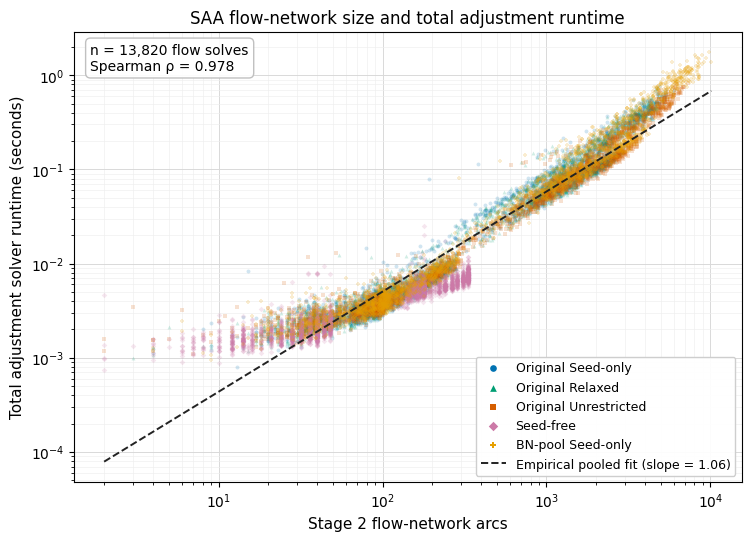

/Users/bobla/Documents/repos/PopSyn_Monash/IO/output/full_household_analysis/paper_section_4_5/flow_network_scaling.png
/Users/bobla/Documents/repos/PopSyn_Monash/IO/output/full_household_analysis/paper_section_4_5/flow_network_scaling.pdf


In [6]:
mpl.rcParams.update({
    'font.family': 'DejaVu Sans',
    'font.size': 10,
    'axes.labelsize': 11,
    'axes.titlesize': 12,
    'legend.fontsize': 9,
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
})
fig, ax = plt.subplots(figsize=(7.4, 5.3), constrained_layout=True)

for policy in RUNS:
    group = points.loc[points['policy'] == policy]
    ax.scatter(
        group['flow_arc_count'], group[TIME_COLUMN],
        s=8, marker=MARKERS[policy], color=COLORS[policy], alpha=0.18,
        linewidths=0, label=policy, rasterized=True,
    )

# Pooled log-linear descriptive trend; it is not presented as a complexity bound.
log_x = np.log10(points['flow_arc_count'].to_numpy())
log_y = np.log10(points[TIME_COLUMN].to_numpy())
slope, intercept = np.polyfit(log_x, log_y, 1)
x_line = np.geomspace(points['flow_arc_count'].min(), points['flow_arc_count'].max(), 300)
y_line = 10 ** (intercept + slope * np.log10(x_line))
ax.plot(x_line, y_line, color='#222222', linestyle='--', linewidth=1.4,
        label=f'Empirical pooled fit (slope = {slope:.2f})')

pooled_rho = correlations.loc[correlations['policy'] == 'All SAA variants', 'spearman_rho'].iat[0]
ax.text(
    0.025, 0.975, f'n = {len(points):,} flow solves\nSpearman ρ = {pooled_rho:.3f}',
    transform=ax.transAxes, ha='left', va='top',
    bbox={'boxstyle': 'round,pad=0.35', 'facecolor': 'white', 'edgecolor': '#BBBBBB', 'alpha': 0.92},
)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('Stage 2 flow-network arcs')
ax.set_ylabel('Total adjustment solver runtime (seconds)')
ax.set_title('SAA flow-network size and total adjustment runtime')
ax.grid(True, which='major', color='#D9D9D9', linewidth=0.7)
ax.grid(True, which='minor', color='#EEEEEE', linewidth=0.45)
ax.set_axisbelow(True)
legend = ax.legend(loc='lower right', frameon=True, framealpha=0.95, markerscale=1.7)
for handle in legend.legend_handles:
    if hasattr(handle, 'set_alpha'):
        handle.set_alpha(1.0)

png_path = REPORT_DIR / 'flow_network_scaling.png'
pdf_path = REPORT_DIR / 'flow_network_scaling.pdf'
fig.savefig(png_path, dpi=350, bbox_inches='tight')
fig.savefig(pdf_path, bbox_inches='tight')
caption = (
    f'Figure X. Relationship between second-stage flow-network arc count and total adjustment '
    f'solver runtime across {len(points):,} SAA adjustment problems. Both axes use logarithmic '
    f'scales. Each point represents one POA–attribute adjustment, with colours and symbols '
    f'distinguishing SAA configurations. Runtime includes first-stage optimisation, second-stage '
    f'optimisation, and flow-construction overhead, whereas the arc count describes the second-stage '
    f'network. The dashed line is a pooled empirical log–log fit (slope = {slope:.2f}); it is not a '
    f'theoretical complexity bound. Spearman’s correlation is {pooled_rho:.3f}.'
)
(REPORT_DIR / 'flow_network_scaling_caption.txt').write_text(caption + '\n', encoding='utf-8')
plt.show()
print(png_path)
print(pdf_path)

## Interpretation

The figure tests computational scaling at the level of individual POA–attribute adjustment problems. A strong positive association means that the number of arcs is a useful empirical measure of SAA problem size. The dashed line visibly underestimates runtimes for small networks, consistent with fixed graph-construction and solver-initialisation costs. Its slope must not be interpreted as a formal asymptotic complexity result because policies, attributes, graph structure, two-stage overhead, and hardware scheduling all vary across observations.

The previously reported correlation of 0.984 used Stage 2 arc count and Stage 2 `network_simplex` solve time. The figure reports 0.978 because its y-axis is total adjustment runtime, including Stage 1 and setup overhead. Both values are correct for their stated timing definitions; 0.978 is the value applicable to this figure.